# Regional on-demand extremes and nested scales

**Atlas source reading copy · browser-network**

[Course guide](index.ipynb) · [Pinned original](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/0e32b2477ba5c0030985e25f1071d94cddabf130/content/28-regional-extremes.ipynb)



Browser-only piplite prepares numpy, matplotlib, pandas, xarray and ipywidgets. Calculations use earthlab.py and original synthetic arrays, not observations or real Digital Twin outputs. Optional widget controls need the source frontend; static figures and numerical results provide alternatives. Real DestinE accounts, Polytope/Data Lake services, GRIB/netCDF decoding and HPC remain explicit source/native continuations. No credentials or service requests are required for these defaults.

**Provenance:** `content/28-regional-extremes.ipynb` at `0e32b2477ba5c0030985e25f1071d94cddabf130`; original SHA-256 `9bc7783e6b2122c1df3d28753499e33c8962a09c16df80380123d35df55bea40`. Original code MIT; original prose, generated numerical data and cleared artwork CC BY 4.0, with attribution and Atlas adaptation notice. Official DestinE references/datasets are linked context, not copied inputs.

**Verification:** imported by static inspection; saved upstream outputs cleared. Runtime compatibility is separate from executed verification. See the course guide for dependencies, excluded assets, aliases and original credits.


![Original abstract globe and synthetic weather streamlines](assets/splash.png)

# Regional on-demand extremes and nested scales

**Lesson 28 · Original synthetic data · Independent educational project**

## Objectives

Compare coarse and fine sampling of a localized event; measure what a coarse grid misses.

[Previous](27-ai-validation.ipynb) · [Notebook source](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/content/28-regional-extremes.ipynb) · [Next](29-land.ipynb)

[Open this notebook in JupyterLite](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/lab/index.html?path=28-regional-extremes.ipynb) — public deployment pending until verified. For a local build, open the matching filename from the Lab file browser.

Run every code cell in order. The first run in JupyterLite downloads browser packages; it needs an internet connection. No account or credentials are used. The interactive visual lessons use ipywidgets, and the gallery provides additional live controls.

## Prepare the browser-sized environment

The shared `earthlab.py` helper lives beside every notebook. The same source notebook is used by the book and Lab.

In [1]:
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "matplotlib", "pandas", "xarray", "ipywidgets"])
import numpy as np
import matplotlib.pyplot as plt
import earthlab as lab
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(lab.PROVENANCE)

Original synthetic teaching data; not observations or DestinE model output


## Worked experiment

Run this original experiment and inspect both its figure and numerical checks.

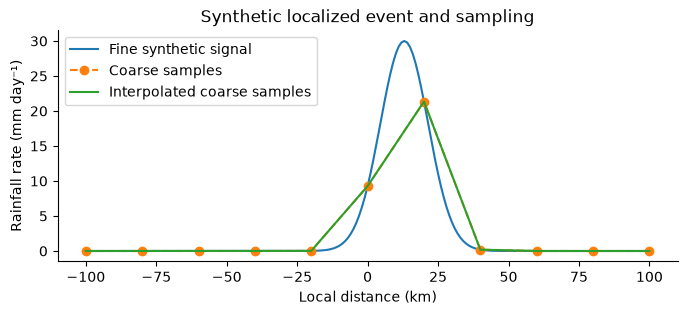

Coarse interpolation error: 3.369 mm/day


In [2]:
coarse = np.linspace(-100, 100, 11)
fine = np.linspace(-100, 100, 201)
def event(x): return 30*np.exp(-((x-13)/12)**2)
coarse_rain, fine_rain = event(coarse), event(fine)
interpolated = np.interp(fine, coarse, coarse_rain)
assert fine_rain.max() >= coarse_rain.max()
error = np.sqrt(np.mean((interpolated-fine_rain)**2))
assert error > 0
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(fine, fine_rain, label="Fine synthetic signal")
ax.plot(coarse, coarse_rain, "o--", label="Coarse samples")
ax.plot(fine, interpolated, label="Interpolated coarse samples")
ax.set(xlabel="Local distance (km)", ylabel="Rainfall rate (mm day⁻¹)", title="Synthetic localized event and sampling")
ax.legend(); plt.show()
print(f"Coarse interpolation error: {error:.3f} mm/day")

## Exercise

Shift the event center onto a coarse grid point. Compare peak error and integrated rainfall; explain why a finer display cannot create missing dynamics.

Add a code cell with your modification and at least one assertion that would catch an incorrect result. Keep the original experiment as a reference.

## Interpretation and limits

Weather-Induced Extremes DT includes global and regional on-demand capabilities described by ECMWF. Regional runs require model initialization, boundaries, configuration, compute allocations and authorized orchestration. This local resolution experiment neither downscales a real event nor submits a simulation.

**Check your reasoning:** identify one result the code establishes and one conclusion the demonstration cannot establish.

## References and provenance

- [Conceptual or software reference](https://destine.ecmwf.int/weather-induced-extremes-digital-twin/) — linked for background; no text, external notebook code or data were copied.
- [Destination Earth initiative source index](https://github.com/destination-earth/DestinE).
- Generated arrays and equations: original project teaching material, CC BY 4.0; helper code: MIT. No authentic DestinE outputs or observational datasets are used.
- The abstract splash was generated for this project. See the repository's [attribution record](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/ATTRIBUTIONS.md).